In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression

In [10]:
df_change_my_view = pd.read_csv('./data/data_full_story.csv')
df_change_my_view

,name,story_score,agency_score,event_score,world_score,suspense_score,surprise_score,curiosity_score
0,t1_c95k50u,0.000000,1.000000,1.000000,1.000000,2.75,2.25,1.75
1,t1_c95mz3n,0.857143,4.000000,5.000000,1.000000,2.75,2.75,3.25
2,t1_c95l4my,0.857143,4.000000,4.000000,1.000000,2.75,3.25,3.50
3,t1_c95mcms,0.857143,5.000000,5.000000,1.000000,3.25,4.00,2.50
4,t3_1aenyc,1.000000,5.000000,5.000000,3.666667,2.75,3.50,3.75
...,...,...,...,...,...,...,...,...
615,t1_cauc7tb,0.000000,1.000000,1.000000,1.000000,2.50,2.75,2.25
616,t1_caue431,0.000000,1.000000,1.000000,1.000000,1.00,1.50,1.50
617,t1_ck496qz,0.571429,2.666667,2.666667,1.000000,2.50,2.75,3.25
618,t1_chkfbo3,0.857143,5.000000,3.666667,3.333333,1.75,2.00,2.75


#### 2. Scatterplots of the Data

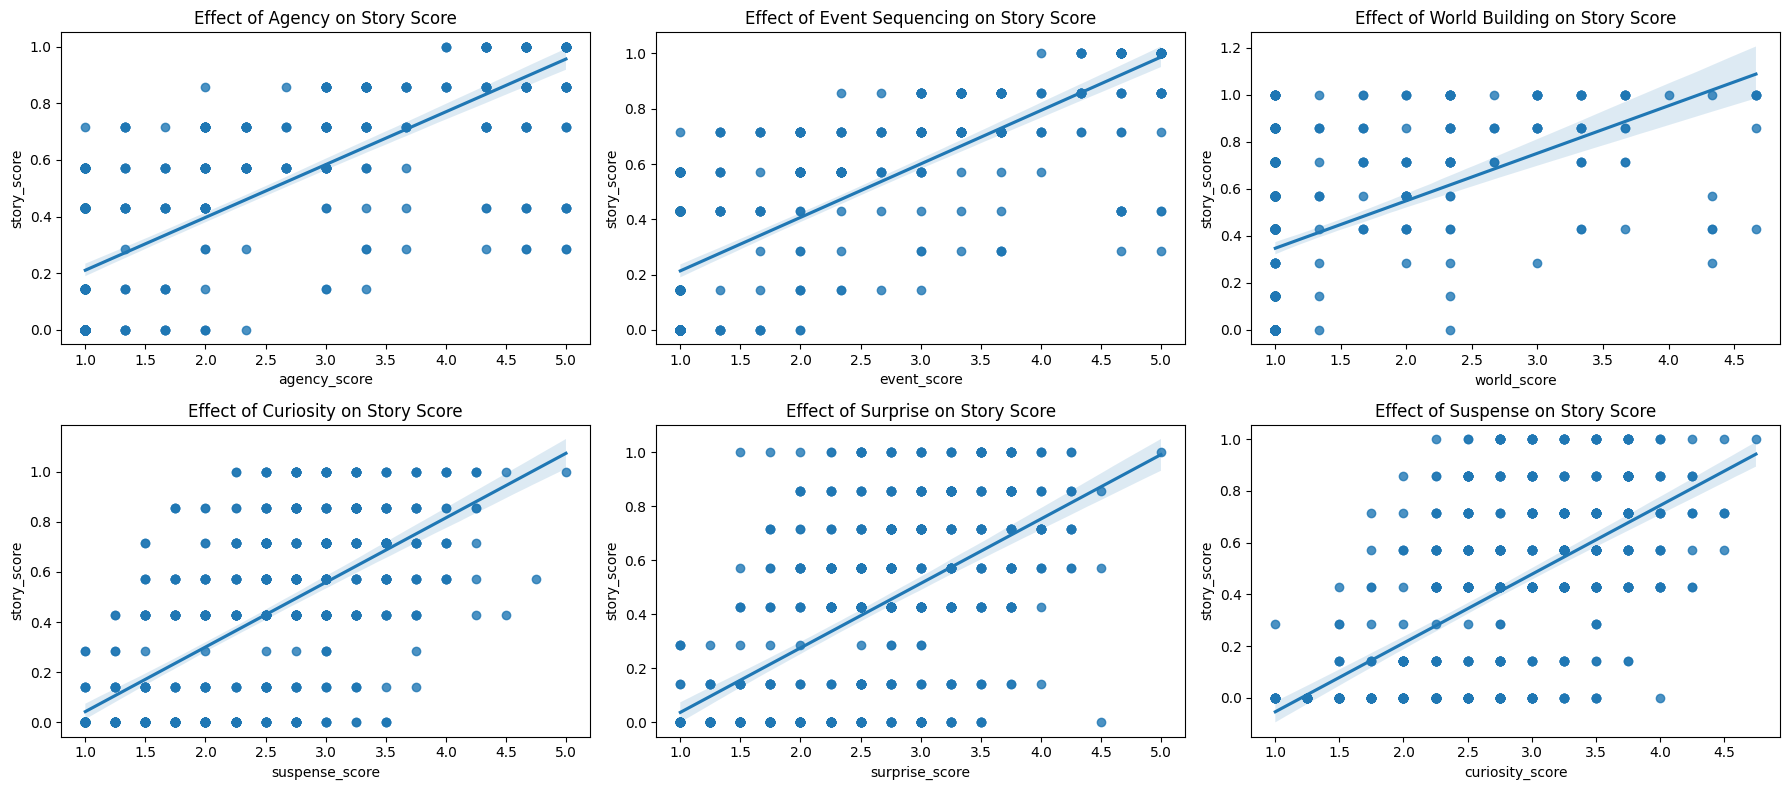

In [37]:
# Create 6 scatterplots
fig, axes = plt.subplots(2, 3, figsize=(18, 8))

sns.regplot(x='agency_score', y='story_score', data=df_change_my_view, ax=axes[0,0]).set_title('Effect of Agency on Story Score')
sns.regplot(x='event_score', y='story_score', data=df_change_my_view, ax=axes[0,1]).set_title('Effect of Event Sequencing on Story Score')
sns.regplot(x='world_score', y='story_score', data=df_change_my_view, ax=axes[0,2]).set_title('Effect of World Building on Story Score')
sns.regplot(x='suspense_score', y='story_score', data=df_change_my_view, ax=axes[1,0]).set_title('Effect of Curiosity on Story Score')
sns.regplot(x='surprise_score', y='story_score', data=df_change_my_view, ax=axes[1,1]).set_title('Effect of Surprise on Story Score')
sns.regplot(x='curiosity_score', y='story_score', data=df_change_my_view, ax=axes[1,2]).set_title('Effect of Suspense on Story Score')

# Plot scatterplots
plt.tight_layout()
plt.show()

In [48]:
independent_variables = ['agency_score', 'event_score', 'world_score', 'suspense_score', 'surprise_score', 'curiosity_score']

In [61]:
def simple_lr(independent_variable):
    X = df_change_my_view[[independent_variable]]
    y = df_change_my_view['story_score']

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    model = LinearRegression()
    model.fit(X_train, y_train)

    slope = model.coef_[0]
    intercept = model.intercept_

    return print(f"{independent_variable}: Coefficient (Slope): {slope} | Intercept: {intercept}")

In [64]:
for independent_variable in independent_variables:
    X = df_change_my_view[[independent_variable]]
    y = df_change_my_view['story_score']

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    model = LinearRegression()
    model.fit(X_train, y_train)

    slope = model.coef_[0]
    intercept = model.intercept_

    print(f"{independent_variable}: Coefficient (Slope): {slope} | Intercept: {intercept}")

    y_pred = model.predict(X_test)
    predictions = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
    print(predictions.head())

agency_score: Coefficient (Slope): 0.17785720679617575 | Intercept: 0.04034692896269332
       Actual  Predicted
49   0.428571   0.277490
584  0.000000   0.218204
82   0.000000   0.218204
305  0.857143   0.633204
109  0.428571   0.218204
event_score: Coefficient (Slope): 0.1852531830625699 | Intercept: 0.03638750049472833
       Actual  Predicted
49   0.428571   0.653898
584  0.000000   0.221641
82   0.000000   0.221641
305  0.857143   0.653898
109  0.428571   0.221641
world_score: Coefficient (Slope): 0.19634791815936253 | Intercept: 0.1478855374742336
       Actual  Predicted
49   0.428571   0.344233
584  0.000000   0.344233
82   0.000000   0.344233
305  0.857143   0.344233
109  0.428571   0.344233
suspense_score: Coefficient (Slope): 0.2442933063393648 | Intercept: -0.18988042515500436
       Actual  Predicted
49   0.428571   0.420853
584  0.000000   0.054413
82   0.000000   0.054413
305  0.857143   0.604073
109  0.428571   0.481926
surprise_score: Coefficient (Slope): 0.23643933750